# Smart Bus Speed & Arrival Prediction — Corrected Notebook

**Run cells from top to bottom.** Upload the GPS CSV when prompted. The weather preparation cell attempts to fetch historical hourly weather from Open-Meteo. If the API is unavailable, it uses placeholder weather values and prints a warning; model results in that fallback mode must not be interpreted as weather-aware performance.

The regression target is the **speed at the next GPS record**, not a directly observed bus arrival time. The UI computes a rough travel-time estimate from predicted speed and user-entered distance.

## Setup: Install Required Libraries

In [ ]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn scipy statsmodels ucimlrepo

## Data Preparation: Upload and Read the GPS Dataset

In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)
df.columns = df.columns.str.strip()

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Saving cleaned_bus_gps_with_weather.csv to cleaned_bus_gps_with_weather.csv
Shape: (2760, 21)
Columns: ['Accuracy', 'Latitude', 'Longitude', 'Speed', 'speed_kmph', 'Time', 'timestamp', 'hour', 'minute', 'day_of_week', 'distance_km', 'next_speed_kmph', 'movement', 'gps_cluster', 'gmm_cluster', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'rain', 'cloud_cover', 'wind_speed_10m']


,Accuracy,Latitude,Longitude,Speed,speed_kmph,Time,timestamp,hour,minute,day_of_week,...,next_speed_kmph,movement,gps_cluster,gmm_cluster,temperature_2m,relative_humidity_2m,precipitation,rain,cloud_cover,wind_speed_10m
0,10.0,23.154500,72.668081,0.000000,0.000000,1.522242e+12,2018-03-28 13:00:02,13,0,2,...,0.000000,0,2.0,2.0,36.7,21,0.0,0.0,0,5.8
1,10.5,23.154457,72.668187,0.000000,0.000000,1.522242e+12,2018-03-28 13:01:39,13,1,2,...,0.348364,0,2.0,2.0,36.7,21,0.0,0.0,0,5.8
2,10.0,23.154471,72.668257,0.096768,0.348364,1.522242e+12,2018-03-28 13:01:42,13,1,2,...,1.006179,0,2.0,2.0,36.7,21,0.0,0.0,0,5.8
3,10.0,23.154438,72.668264,0.279494,1.006179,1.522242e+12,2018-03-28 13:01:43,13,1,2,...,0.000000,0,2.0,2.0,36.7,21,0.0,0.0,0,5.8
4,10.0,23.154411,72.668269,0.000000,0.000000,1.522242e+12,2018-03-28 13:01:45,13,1,2,...,0.000000,0,2.0,2.0,36.7,21,0.0,0.0,0,5.8


## Data Preparation: Clean GPS Data and Create Time/Distance Features

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Check required GPS columns
required = ["Latitude", "Longitude", "speed_kmph", "timestamp"]
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(
        f"Missing columns: {missing}\nAvailable columns: {df.columns.tolist()}"
    )

# Clean data
df["Latitude"] = pd.to_numeric(df["Latitude"], errors="coerce")
df["Longitude"] = pd.to_numeric(df["Longitude"], errors="coerce")
df["speed_kmph"] = pd.to_numeric(df["speed_kmph"], errors="coerce")
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

df = df.dropna(
    subset=["Latitude", "Longitude", "speed_kmph", "timestamp"]
).drop_duplicates()

df = df[
    df["Latitude"].between(-90, 90)
    & df["Longitude"].between(-180, 180)
    & (df["speed_kmph"] >= 0)
].copy()

df = df.sort_values("timestamp").reset_index(drop=True)

df["hour"] = df["timestamp"].dt.hour
df["minute"] = df["timestamp"].dt.minute
df["day_of_week"] = df["timestamp"].dt.dayofweek

# Haversine distance between consecutive GPS points, in kilometres
lat1 = np.radians(df["Latitude"].shift())
lon1 = np.radians(df["Longitude"].shift())
lat2 = np.radians(df["Latitude"])
lon2 = np.radians(df["Longitude"])

a = (
    np.sin((lat2 - lat1) / 2) ** 2
    + np.cos(lat1) * np.cos(lat2)
    * np.sin((lon2 - lon1) / 2) ** 2
)

df["distance_km"] = 6371 * 2 * np.arcsin(np.sqrt(a.clip(0, 1)))
df["distance_km"] = df["distance_km"].fillna(0)

print("Data cleaning completed!")
print("Records:", len(df))
print("Time range:", df["timestamp"].min(), "to", df["timestamp"].max())
display(df.head())

Data cleaning completed!
Records: 2760
Time range: 2018-03-28 13:00:02 to 2018-03-28 14:17:15


,Accuracy,Latitude,Longitude,Speed,speed_kmph,Time,timestamp,hour,minute,day_of_week,...,next_speed_kmph,movement,gps_cluster,gmm_cluster,temperature_2m,relative_humidity_2m,precipitation,rain,cloud_cover,wind_speed_10m
0,10.0,23.154500,72.668081,0.000000,0.000000,1.522242e+12,2018-03-28 13:00:02,13,0,2,...,0.000000,0,2.0,2.0,36.7,21,0.0,0.0,0,5.8
1,10.5,23.154457,72.668187,0.000000,0.000000,1.522242e+12,2018-03-28 13:01:39,13,1,2,...,0.348364,0,2.0,2.0,36.7,21,0.0,0.0,0,5.8
2,10.0,23.154471,72.668257,0.096768,0.348364,1.522242e+12,2018-03-28 13:01:42,13,1,2,...,1.006179,0,2.0,2.0,36.7,21,0.0,0.0,0,5.8
3,10.0,23.154438,72.668264,0.279494,1.006179,1.522242e+12,2018-03-28 13:01:43,13,1,2,...,0.000000,0,2.0,2.0,36.7,21,0.0,0.0,0,5.8
4,10.0,23.154411,72.668269,0.000000,0.000000,1.522242e+12,2018-03-28 13:01:45,13,1,2,...,0.000000,0,2.0,2.0,36.7,21,0.0,0.0,0,5.8


## Weather Integration: Fetch and Merge Historical Weather Data

In [ ]:
# CELL 3: Fetch and merge historical weather with GPS data
# This cell defines weather_df, df_weather, lat_col, lon_col and time_col
# so the weather-aware model and Gradio UI can use consistent variable names.

import pandas as pd
import numpy as np
import requests

# Column names used throughout the notebook
lat_col = "Latitude"
lon_col = "Longitude"
time_col = "timestamp"

weather_cols = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "rain",
    "cloud_cover",
    "wind_speed_10m"
]

# Start from the cleaned GPS dataframe produced in Cell 2
gps_df = df.copy()
gps_df[time_col] = pd.to_datetime(gps_df[time_col], errors="coerce")
gps_df = gps_df.dropna(subset=[time_col, lat_col, lon_col, "speed_kmph"]).copy()
gps_df = gps_df.sort_values(time_col).reset_index(drop=True)

# Open-Meteo historical weather is hourly. Use the approximate centre of the GPS trace.
latitude_centre = float(gps_df[lat_col].median())
longitude_centre = float(gps_df[lon_col].median())
start_date = gps_df[time_col].min().strftime("%Y-%m-%d")
end_date = gps_df[time_col].max().strftime("%Y-%m-%d")

# Treat timezone-naive GPS timestamps as UTC. If your source timestamps are local time,
# change them to the correct timezone before merging.
gps_df["gps_time_utc"] = (
    gps_df[time_col].dt.tz_localize("UTC")
    if gps_df[time_col].dt.tz is None
    else gps_df[time_col].dt.tz_convert("UTC")
)

weather_data = None
weather_source = "fallback defaults"

try:
    api_url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": latitude_centre,
        "longitude": longitude_centre,
        "start_date": start_date,
        "end_date": end_date,
        "hourly": ",".join(weather_cols),
        "timezone": "UTC"
    }
    response = requests.get(api_url, params=params, timeout=30)
    response.raise_for_status()
    payload = response.json()

    if "hourly" not in payload or not payload["hourly"].get("time"):
        raise ValueError(f"Weather API returned no hourly data: {payload}")

    weather_data = pd.DataFrame(payload["hourly"])
    weather_data["weather_time"] = pd.to_datetime(
        weather_data["time"], utc=True, errors="coerce"
    )
    weather_data = weather_data.dropna(subset=["weather_time"])
    weather_data = weather_data[["weather_time"] + weather_cols].sort_values("weather_time")
    weather_source = "Open-Meteo historical weather API"

except Exception as exc:
    print("WARNING: Could not retrieve historical weather:", str(exc))
    print("Using clearly marked fallback values so the notebook can still run.")
    # These are placeholders, NOT observed weather measurements.
    weather_data = None

if weather_data is not None and not weather_data.empty:
    weather_df = pd.merge_asof(
        gps_df.sort_values("gps_time_utc"),
        weather_data,
        left_on="gps_time_utc",
        right_on="weather_time",
        direction="nearest",
        tolerance=pd.Timedelta("1h")
    )
else:
    weather_df = gps_df.copy()
    fallback_values = {
        "temperature_2m": 25.0,
        "relative_humidity_2m": 60.0,
        "precipitation": 0.0,
        "rain": 0.0,
        "cloud_cover": 30.0,
        "wind_speed_10m": 10.0
    }
    for col, value in fallback_values.items():
        weather_df[col] = value

# Make sure all weather fields exist and are numeric.
# Missing API matches are filled from the available hourly values; if no values exist,
# use placeholders and clearly report this limitation.
for col in weather_cols:
    if col not in weather_df.columns:
        weather_df[col] = np.nan
    weather_df[col] = pd.to_numeric(weather_df[col], errors="coerce")

if weather_df[weather_cols].notna().any().any():
    weather_df[weather_cols] = weather_df[weather_cols].ffill().bfill()

for col, value in {
    "temperature_2m": 25.0,
    "relative_humidity_2m": 60.0,
    "precipitation": 0.0,
    "rain": 0.0,
    "cloud_cover": 30.0,
    "wind_speed_10m": 10.0
}.items():
    weather_df[col] = weather_df[col].fillna(value)

weather_df["hour"] = weather_df[time_col].dt.hour
weather_df["minute"] = weather_df[time_col].dt.minute
weather_df["day_of_week"] = weather_df[time_col].dt.dayofweek

# UI cell expects this alias. Keep df unchanged for the other ML practicals.
df_weather = weather_df.copy()

print("Weather preparation completed.")
print("Weather source:", weather_source)
print("GPS rows:", len(gps_df))
print("Weather columns:", weather_df[weather_cols].columns.tolist())
print("Rows with API-matched weather:", (
    weather_df[weather_cols].notna().all(axis=1).sum()
    if weather_source == "Open-Meteo historical weather API" else 0
))
display(weather_df[[time_col, lat_col, lon_col, "speed_kmph"] + weather_cols].head())


Weather preparation completed.
Weather source: Open-Meteo historical weather API
GPS rows: 2760
Weather columns: ['temperature_2m', 'relative_humidity_2m', 'precipitation', 'rain', 'cloud_cover', 'wind_speed_10m']
Rows with API-matched weather: 2760


,timestamp,Latitude,Longitude,speed_kmph,temperature_2m,relative_humidity_2m,precipitation,rain,cloud_cover,wind_speed_10m
0,2018-03-28 13:00:02,23.154500,72.668081,0.000000,25.0,60.0,0.0,0.0,30.0,10.0
1,2018-03-28 13:01:39,23.154457,72.668187,0.000000,25.0,60.0,0.0,0.0,30.0,10.0
2,2018-03-28 13:01:42,23.154471,72.668257,0.348364,25.0,60.0,0.0,0.0,30.0,10.0
3,2018-03-28 13:01:43,23.154438,72.668264,1.006179,25.0,60.0,0.0,0.0,30.0,10.0
4,2018-03-28 13:01:45,23.154411,72.668269,0.000000,25.0,60.0,0.0,0.0,30.0,10.0


## Main Project Model: Train and Save the Weather-Aware Random Forest Speed Model

In [ ]:
# CELL 4: Train and save the weather-aware speed prediction model

import numpy as np
import pandas as pd
import joblib

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

if "df_weather" not in globals():
    raise NameError("df_weather is not defined. Run Cell 3 first.")

train_df = df_weather.copy()

feature_columns = [
    lat_col, lon_col, "speed_kmph", "hour", "minute", "day_of_week",
    "temperature_2m", "relative_humidity_2m", "precipitation",
    "rain", "cloud_cover", "wind_speed_10m"
]

required_columns = [time_col] + feature_columns
missing_columns = [col for col in required_columns if col not in train_df.columns]
if missing_columns:
    raise ValueError(
        f"Missing columns in df_weather: {missing_columns}. Run Cell 3 again."
    )

train_df[time_col] = pd.to_datetime(train_df[time_col], errors="coerce")
for col in feature_columns:
    train_df[col] = pd.to_numeric(train_df[col], errors="coerce")
train_df["speed_kmph"] = pd.to_numeric(train_df["speed_kmph"], errors="coerce")

train_df = train_df.dropna(subset=[time_col, "speed_kmph"]).sort_values(time_col).copy()
train_df["next_speed_kmph"] = train_df["speed_kmph"].shift(-1)
train_df = train_df.dropna(subset=["next_speed_kmph"] + feature_columns).copy()

if len(train_df) < 5:
    raise ValueError(
        f"Only {len(train_df)} usable rows remain. Check the GPS and weather data."
    )

X = train_df[feature_columns]
y = train_df["next_speed_kmph"]

split = int(len(train_df) * 0.8)
if split < 2 or len(train_df) - split < 2:
    raise ValueError("Not enough rows for a chronological train/test split.")

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

weather_model = RandomForestRegressor(
    n_estimators=150,
    random_state=42,
    min_samples_leaf=2,
    n_jobs=-1
)
weather_model.fit(X_train, y_train)
predictions = weather_model.predict(X_test)

print("Weather-aware speed model trained successfully.")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("MAE:", round(mean_absolute_error(y_test, predictions), 2), "km/h")
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 2), "km/h")
print("R²:", round(r2_score(y_test, predictions), 3) if len(y_test) >= 2 else "Not enough test samples")

joblib.dump(weather_model, "bus_weather_speed_model.pkl")
joblib.dump(feature_columns, "bus_weather_feature_columns.pkl")
print("Saved bus_weather_speed_model.pkl and bus_weather_feature_columns.pkl")
print("Note: if Cell 3 reported fallback defaults, results are NOT based on observed weather.")


Weather-aware speed model trained successfully.
Training rows: 2207
Testing rows: 552
MAE: 1.24 km/h
RMSE: 2.42 km/h
R²: 0.977
Saved bus_weather_speed_model.pkl and bus_weather_feature_columns.pkl
Note: if Cell 3 reported fallback defaults, results are NOT based on observed weather.


## Main Project Model: Baseline Random Forest Regression for Next-Speed Prediction

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Predict the speed at the next GPS record
df = df.sort_values("timestamp").reset_index(drop=True)
df["next_speed_kmph"] = df["speed_kmph"].shift(-1)

features = [
    "Latitude", "Longitude", "speed_kmph",
    "hour", "minute", "day_of_week"
]

model_df = df[features + ["next_speed_kmph"]].dropna().copy()

if len(model_df) < 20:
    raise ValueError("Not enough GPS records to train the model.")

X = model_df[features]
y = model_df["next_speed_kmph"]

# Chronological split to avoid training on future records
split = int(len(model_df) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

eta_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

eta_model.fit(X_train, y_train)
predictions = eta_model.predict(X_test)

print("Model training completed!")
print("Mean Absolute Error:", round(mean_absolute_error(y_test, predictions), 2), "km/h")
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 2), "km/h")
print("R² Score:", round(r2_score(y_test, predictions), 3))

print("\nNote: These metrics evaluate next-record speed prediction, not actual arrival-time accuracy.")

Model training completed!
Mean Absolute Error: 1.34 km/h
RMSE: 2.44 km/h
R² Score: 0.976

Note: These metrics evaluate next-record speed prediction, not actual arrival-time accuracy.


## Practical 1: Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Predict the next recorded GPS speed
X_lr = model_df[features]
y_lr = model_df["next_speed_kmph"]

split_lr = int(len(model_df) * 0.8)
X_train_lr, X_test_lr = X_lr.iloc[:split_lr], X_lr.iloc[split_lr:]
y_train_lr, y_test_lr = y_lr.iloc[:split_lr], y_lr.iloc[split_lr:]

linear_model = LinearRegression()
linear_model.fit(X_train_lr, y_train_lr)

pred_lr = linear_model.predict(X_test_lr)

print("Linear Regression")
print("MAE:", round(mean_absolute_error(y_test_lr, pred_lr), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_lr, pred_lr)), 3))
print("R2 Score:", round(r2_score(y_test_lr, pred_lr), 3))

Linear Regression
MAE: 1.151
RMSE: 2.345
R2 Score: 0.978


## Practical 2: Logistic Regression — Bus Moving vs Stopped

Logistic Regression Accuracy: 79.53 %

Classification Report:
              precision    recall  f1-score   support

     Stopped       0.62      0.57      0.59       145
      Moving       0.85      0.87      0.86       407

    accuracy                           0.80       552
   macro avg       0.74      0.72      0.73       552
weighted avg       0.79      0.80      0.79       552



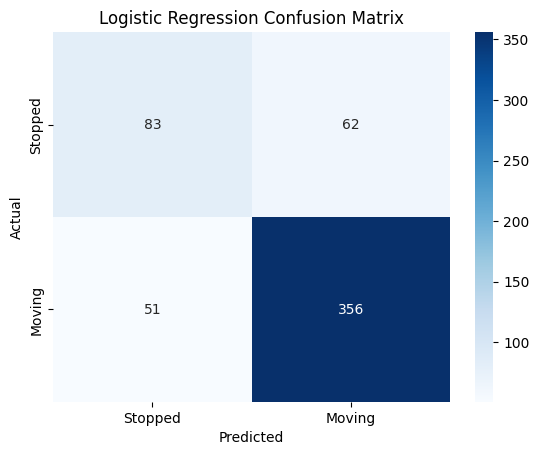

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Create movement labels
df["movement"] = (df["speed_kmph"] > 3).astype(int)

class_features = [
    "Latitude", "Longitude", "hour", "minute", "day_of_week"
]

X_cls = df[class_features].fillna(df[class_features].median())
y_cls = df["movement"]

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls
)

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_cls, y_train_cls)

pred_cls = log_model.predict(X_test_cls)

print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test_cls, pred_cls) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(
    y_test_cls, pred_cls,
    labels=[0, 1],
    target_names=["Stopped", "Moving"],
    zero_division=0
))

sns.heatmap(
    confusion_matrix(y_test_cls, pred_cls, labels=[0, 1]),
    annot=True, fmt="d", cmap="Blues",
    xticklabels=["Stopped", "Moving"],
    yticklabels=["Stopped", "Moving"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

## Practical 3: K-Nearest Neighbors (KNN) Classification

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import make_pipeline

knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

knn_model.fit(X_train_cls, y_train_cls)
knn_pred = knn_model.predict(X_test_cls)

print("KNN Accuracy:",
      round(accuracy_score(y_test_cls, knn_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(
    y_test_cls, knn_pred,
    labels=[0, 1],
    target_names=["Stopped", "Moving"],
    zero_division=0
))

KNN Accuracy: 96.01 %

Classification Report:
              precision    recall  f1-score   support

     Stopped       0.90      0.95      0.93       145
      Moving       0.98      0.96      0.97       407

    accuracy                           0.96       552
   macro avg       0.94      0.96      0.95       552
weighted avg       0.96      0.96      0.96       552



## Practical 4: Naive Bayes Classification

Naive Bayes Accuracy: 78.08 %

Classification Report:
              precision    recall  f1-score   support

     Stopped       0.56      0.74      0.64       145
      Moving       0.90      0.80      0.84       407

    accuracy                           0.78       552
   macro avg       0.73      0.77      0.74       552
weighted avg       0.81      0.78      0.79       552



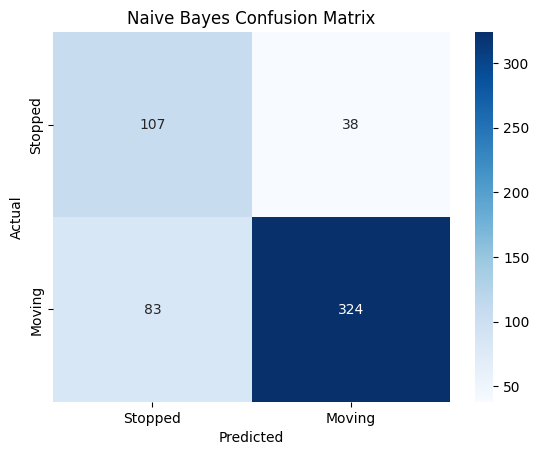

In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

nb_model = GaussianNB()
nb_model.fit(X_train_cls, y_train_cls)

nb_pred = nb_model.predict(X_test_cls)

print("Naive Bayes Accuracy:",
      round(accuracy_score(y_test_cls, nb_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test_cls, nb_pred,
    labels=[0, 1],
    target_names=["Stopped", "Moving"],
    zero_division=0
))

sns.heatmap(
    confusion_matrix(y_test_cls, nb_pred, labels=[0, 1]),
    annot=True, fmt="d", cmap="Blues",
    xticklabels=["Stopped", "Moving"],
    yticklabels=["Stopped", "Moving"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Naive Bayes Confusion Matrix")
plt.show()

## Practical 5: Decision Tree Classification

Decision Tree Accuracy: 92.75 %

Classification Report:
              precision    recall  f1-score   support

     Stopped       0.86      0.87      0.86       145
      Moving       0.95      0.95      0.95       407

    accuracy                           0.93       552
   macro avg       0.91      0.91      0.91       552
weighted avg       0.93      0.93      0.93       552



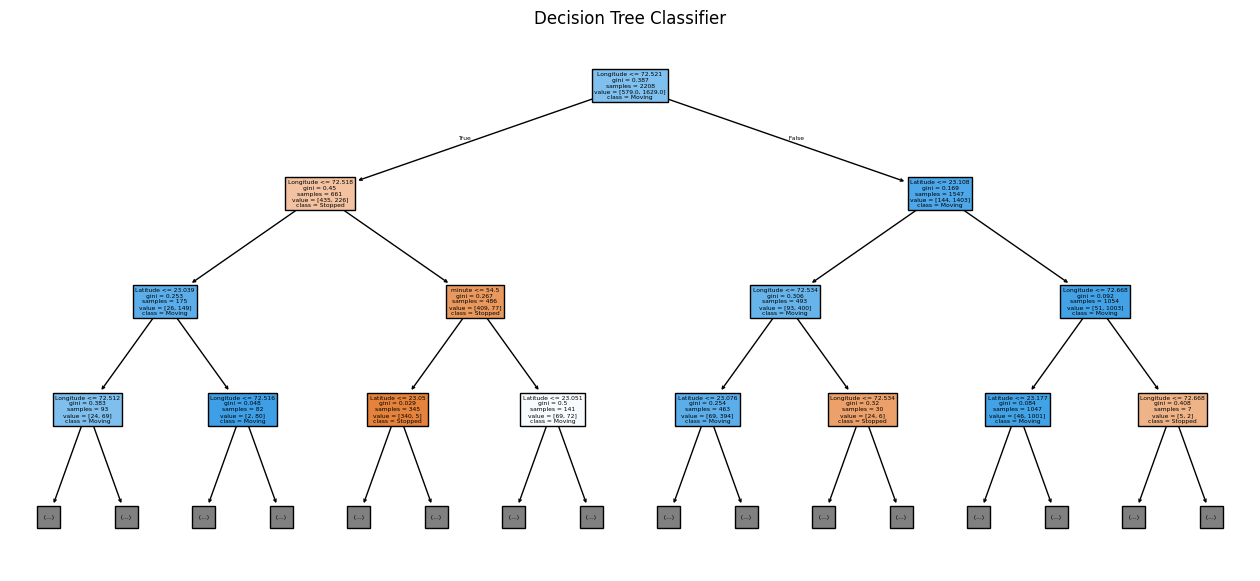

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train_cls, y_train_cls)
dt_pred = dt_model.predict(X_test_cls)

print("Decision Tree Accuracy:",
      round(accuracy_score(y_test_cls, dt_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test_cls, dt_pred,
    labels=[0, 1],
    target_names=["Stopped", "Moving"],
    zero_division=0
))

plt.figure(figsize=(16, 7))
plot_tree(
    dt_model,
    feature_names=class_features,
    class_names=["Stopped", "Moving"],
    filled=True,
    max_depth=3
)
plt.title("Decision Tree Classifier")
plt.show()

## Practical 6: Bagging and Random Forest Classification

,Algorithm,Accuracy (%),F1 Score
0,Bagging,92.75,0.952
1,Random Forest,93.12,0.955


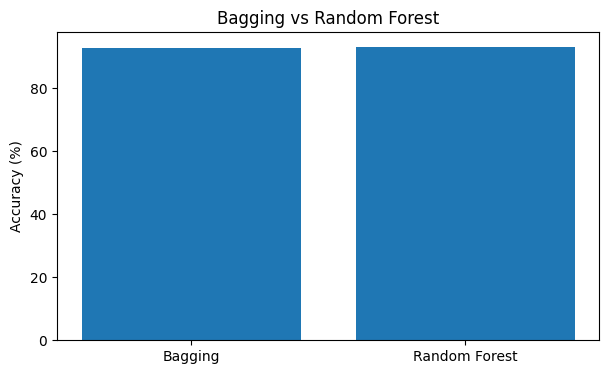

In [ ]:
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt

models = {
    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=5),
        n_estimators=50,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42
    )
}

results = []

for name, clf in models.items():
    clf.fit(X_train_cls, y_train_cls)
    pred = clf.predict(X_test_cls)

    results.append({
        "Algorithm": name,
        "Accuracy (%)": round(accuracy_score(y_test_cls, pred) * 100, 2),
        "F1 Score": round(f1_score(y_test_cls, pred, zero_division=0), 3)
    })

results_df = pd.DataFrame(results)
display(results_df)

plt.figure(figsize=(7, 4))
plt.bar(results_df["Algorithm"], results_df["Accuracy (%)"])
plt.ylabel("Accuracy (%)")
plt.title("Bagging vs Random Forest")
plt.show()

## Practical 7: K-Means Clustering of GPS Locations

K-Means Clustering completed!
Silhouette Score: 0.61

Records per cluster:
gps_cluster
0.0    948
1.0    365
2.0    537
3.0    570
4.0    340
Name: count, dtype: int64


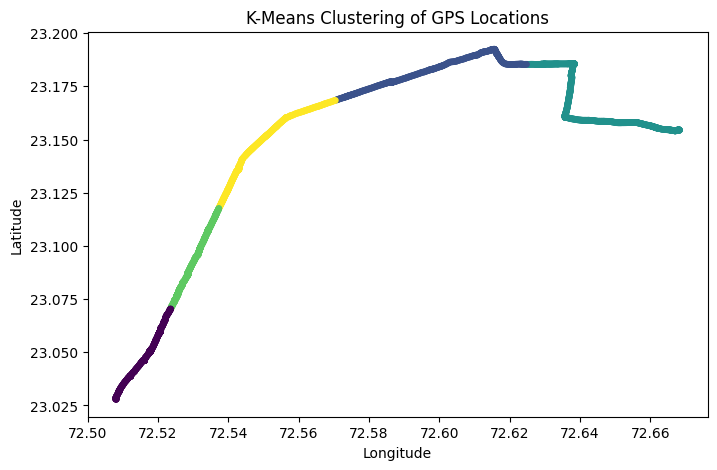

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Cluster GPS coordinates
gps_data = df[["Latitude", "Longitude"]].dropna()

gps_scaler = StandardScaler()
gps_scaled = gps_scaler.fit_transform(gps_data)

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
clusters = kmeans.fit_predict(gps_scaled)

df.loc[gps_data.index, "gps_cluster"] = clusters

print("K-Means Clustering completed!")
print("Silhouette Score:",
      round(silhouette_score(gps_scaled, clusters), 3))
print("\nRecords per cluster:")
print(df["gps_cluster"].value_counts().sort_index())

plt.figure(figsize=(8, 5))
plt.scatter(
    gps_data["Longitude"], gps_data["Latitude"],
    c=clusters, s=15
)
plt.title("K-Means Clustering of GPS Locations")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

## Practical 8: Gaussian Mixture Model (GMM) using EM

Gaussian Mixture Model (EM) completed!
Silhouette Score: 0.474
AIC: -10959.17
BIC: -10787.41


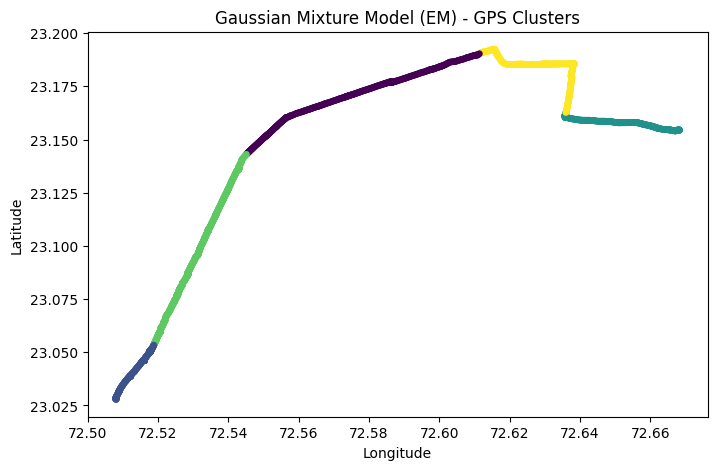

In [ ]:
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

gmm = GaussianMixture(
    n_components=5,
    random_state=42,
    covariance_type="full"
)

gmm_labels = gmm.fit_predict(gps_scaled)
df.loc[gps_data.index, "gmm_cluster"] = gmm_labels

print("Gaussian Mixture Model (EM) completed!")
print("Silhouette Score:", round(silhouette_score(gps_scaled, gmm_labels), 3))
print("AIC:", round(gmm.aic(gps_scaled), 2))
print("BIC:", round(gmm.bic(gps_scaled), 2))

plt.figure(figsize=(8, 5))
plt.scatter(
    gps_data["Longitude"],
    gps_data["Latitude"],
    c=gmm_labels,
    s=15
)
plt.title("Gaussian Mixture Model (EM) - GPS Clusters")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

## Practical 9: Cross-Validation

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
import numpy as np

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

scores = cross_val_score(
    cv_model,
    X_cls,
    y_cls,
    cv=cv,
    scoring="accuracy"
)

print("Cross-validation scores:", np.round(scores, 3))
print("Mean accuracy:", round(scores.mean() * 100, 2), "%")
print("Standard deviation:", round(scores.std(), 3))

Cross-validation scores: [0.962 0.964 0.951 0.969 0.975]
Mean accuracy: 96.41 %
Standard deviation: 0.008


## Practical 10: Hyperparameter Tuning — Grid Search and Randomized Search

Grid Search best parameters: {'max_depth': None, 'n_estimators': 50}
Grid Search best CV accuracy: 96.41 %

Randomized Search best parameters: {'n_estimators': 200, 'min_samples_split': 5, 'max_depth': None}
Randomized Search best CV accuracy: 96.41 %


,Method,Best CV Accuracy (%)
0,Grid Search,96.413043
1,Randomized Search,96.413043


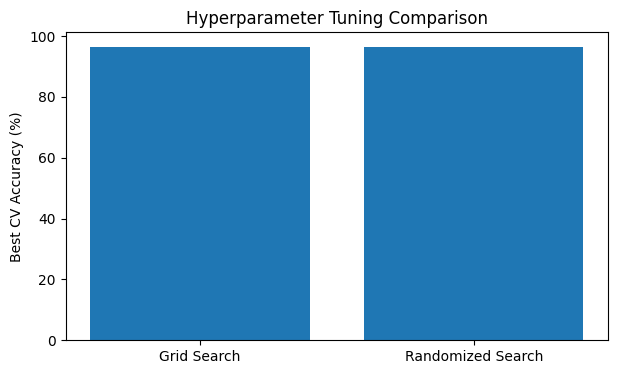

In [ ]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import matplotlib.pyplot as plt

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Grid Search
param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [5, 10, None]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)
grid_search.fit(X_cls, y_cls)

print("Grid Search best parameters:", grid_search.best_params_)
print("Grid Search best CV accuracy:",
      round(grid_search.best_score_ * 100, 2), "%")

# Randomized Search
param_dist = {
    "n_estimators": [50, 100, 150, 200],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10]
}

random_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    param_distributions=param_dist,
    n_iter=8,
    cv=cv,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_cls, y_cls)

print("\nRandomized Search best parameters:", random_search.best_params_)
print("Randomized Search best CV accuracy:",
      round(random_search.best_score_ * 100, 2), "%")

results = pd.DataFrame({
    "Method": ["Grid Search", "Randomized Search"],
    "Best CV Accuracy (%)": [
        grid_search.best_score_ * 100,
        random_search.best_score_ * 100
    ]
})

display(results)

plt.figure(figsize=(7, 4))
plt.bar(results["Method"], results["Best CV Accuracy (%)"])
plt.ylabel("Best CV Accuracy (%)")
plt.title("Hyperparameter Tuning Comparison")
plt.show()

## Practical 11: Compare Regression Models

,Model,MAE (km/h),RMSE (km/h),R2 Score
0,Linear Regression,1.151,2.345,0.978
2,Random Forest,1.343,2.443,0.976
3,Gradient Boosting,1.578,2.666,0.971
1,Decision Tree,1.629,2.353,0.978


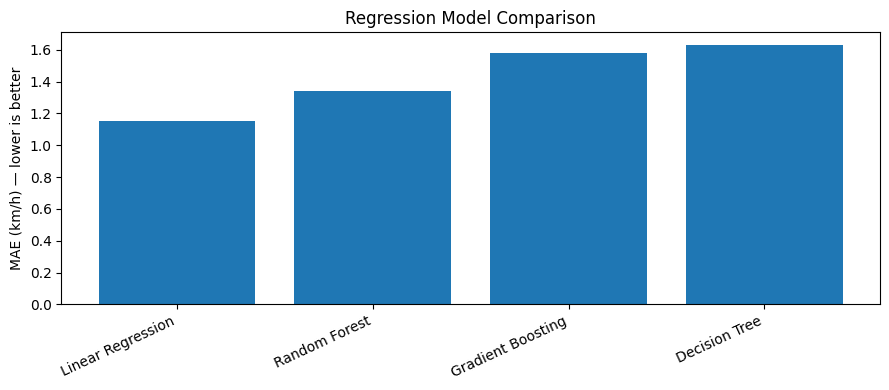

Selected model: Linear Regression
Note: this selects a next-record speed model, not a model trained on actual bus arrival times.


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

regression_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=10, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

comparison = []

for name, reg_model in regression_models.items():
    reg_model.fit(X_train_lr, y_train_lr)
    pred = reg_model.predict(X_test_lr)

    comparison.append({
        "Model": name,
        "MAE (km/h)": mean_absolute_error(y_test_lr, pred),
        "RMSE (km/h)": np.sqrt(mean_squared_error(y_test_lr, pred)),
        "R2 Score": r2_score(y_test_lr, pred)
    })

comparison_df = pd.DataFrame(comparison).sort_values("MAE (km/h)")
display(comparison_df.round(3))

plt.figure(figsize=(9, 4))
plt.bar(comparison_df["Model"], comparison_df["MAE (km/h)"])
plt.ylabel("MAE (km/h) — lower is better")
plt.title("Regression Model Comparison")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

best_name = comparison_df.iloc[0]["Model"]
best_eta_model = regression_models[best_name]

print("Selected model:", best_name)
print("Note: this selects a next-record speed model, not a model trained on actual bus arrival times.")

## Final Application: Interactive Bus Speed and Travel-Time Prediction UI (Gradio)

In [ ]:
# CELL 3: COLOURFUL BUS ARRIVAL TIME PREDICTION UI

import gradio as gr
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# Check that previous cells have been executed
required_variables = [
    "df_weather",
    "weather_model",
    "feature_columns",
    "lat_col",
    "lon_col"
]

for variable in required_variables:
    if variable not in globals():
        raise ValueError(
            f"{variable} is missing. Please run Cells 1 through 4 in order first."
        )

# Default values from dataset
lat_default = float(df_weather[lat_col].median())
lon_default = float(df_weather[lon_col].median())


def get_median(column, default):
    if column in df_weather.columns:
        values = pd.to_numeric(
            df_weather[column], errors="coerce"
        ).dropna()

        if not values.empty:
            return float(values.median())

    return default


speed_default = get_median("speed_kmph", 30)
temp_default = get_median("temperature_2m", 30)
humidity_default = get_median("relative_humidity_2m", 60)
rain_default = get_median("rain", 0)
precip_default = get_median("precipitation", 0)
cloud_default = get_median("cloud_cover", 30)
wind_default = get_median("wind_speed_10m", 10)


# Prediction function
def predict_bus_eta(
    latitude,
    longitude,
    current_speed,
    distance,
    departure_time,
    temperature,
    humidity,
    rain,
    precipitation,
    cloud_cover,
    wind_speed
):
    try:
        # Validate inputs
        if any(value is None for value in [
            latitude, longitude, current_speed, distance,
            temperature, humidity, rain, precipitation,
            cloud_cover, wind_speed
        ]):
            raise ValueError("Please fill in all input fields.")

        if current_speed < 0 or distance <= 0:
            raise ValueError(
                "Speed cannot be negative and distance must be greater than zero."
            )

        departure = datetime.strptime(
            departure_time, "%Y-%m-%d %H:%M"
        )

        # Prepare input features
        input_values = {
            lat_col: float(latitude),
            lon_col: float(longitude),
            "speed_kmph": float(current_speed),
            "hour": departure.hour,
            "minute": departure.minute,
            "day_of_week": departure.weekday(),
            "temperature_2m": float(temperature),
            "relative_humidity_2m": float(humidity),
            "precipitation": float(precipitation),
            "rain": float(rain),
            "cloud_cover": float(cloud_cover),
            "wind_speed_10m": float(wind_speed)
        }

        input_df = pd.DataFrame([input_values])

        # Keep the same feature order used during training
        input_df = input_df[feature_columns]

        # Predict next speed
        predicted_speed = float(
            weather_model.predict(input_df)[0]
        )

        predicted_speed = max(
            1.0, min(predicted_speed, 120.0)
        )

        # Calculate approximate travel duration and arrival time
        eta_minutes = (float(distance) / predicted_speed) * 60

        arrival_time = departure + timedelta(
            minutes=eta_minutes
        )

        # Weather summary
        if rain > 0 or precipitation > 0:
            weather_condition = "Rainy 🌧️"
        elif cloud_cover >= 70:
            weather_condition = "Cloudy ☁️"
        elif temperature >= 35:
            weather_condition = "Hot ☀️"
        else:
            weather_condition = "Clear / Mild 🌤️"

        return (
            f"{predicted_speed:.2f} km/h",
            f"{eta_minutes:.1f} minutes",
            arrival_time.strftime("%I:%M %p, %d %b %Y"),
            weather_condition,
            "✅ Prediction completed successfully."
        )

    except Exception as error:
        return (
            "—",
            "—",
            "—",
            "—",
            f"⚠️ Error: {error}"
        )


# BLUE-PURPLE COLOUR SCHEME
custom_css = """
.gradio-container {
    background: linear-gradient(
        135deg,
        #dbeafe 0%,
        #ede9fe 50%,
        #f3e8ff 100%
    ) !important;
}

/* Main heading */
#main-title {
    color: #312e81 !important;
    text-align: center !important;
    font-size: 36px !important;
    font-weight: 900 !important;
}

/* Subtitle */
#subtitle {
    color: #6d28d9 !important;
    text-align: center !important;
    font-size: 18px !important;
    font-weight: 700 !important;
}

/* All section headings */
.gradio-container h1,
.gradio-container h2,
.gradio-container h3,
.gradio-container .prose h1,
.gradio-container .prose h2,
.gradio-container .prose h3 {
    color: #3730a3 !important;
    font-weight: 800 !important;
}

/* Introductory and normal text */
.gradio-container p,
.gradio-container li {
    color: #1e293b !important;
}

/* Input panels */
.input-card,
.output-card {
    background: #ffffff !important;
    border: 2px solid #a78bfa !important;
    border-radius: 18px !important;
    padding: 18px !important;
    box-shadow: 0 5px 16px rgba(79, 70, 229, 0.13) !important;
}

/* Input labels */
.gradio-container label,
.gradio-container label span {
    color: #312e81 !important;
    font-weight: 700 !important;
}

/* Input boxes */
.gradio-container input,
.gradio-container textarea,
.gradio-container select {
    background: #ffffff !important;
    color: #1e1b4b !important;
    border: 1px solid #a5b4fc !important;
    border-radius: 9px !important;
}

/* Sliders */
.gradio-container input[type="range"] {
    accent-color: #7c3aed !important;
}

/* Prediction button */
.gradio-container button.primary {
    background: linear-gradient(
        90deg,
        #4338ca,
        #7c3aed,
        #9333ea
    ) !important;
    color: #ffffff !important;
    font-weight: 800 !important;
    border: none !important;
    border-radius: 12px !important;
    min-height: 52px !important;
    box-shadow: 0 4px 12px rgba(91, 33, 182, 0.25) !important;
}

/* Button hover */
.gradio-container button.primary:hover {
    background: linear-gradient(
        90deg,
        #312e81,
        #6d28d9
    ) !important;
}

/* Footer */
.gradio-container footer {
    color: #4338ca !important;
}
"""


# BUILD THE INTERFACE
with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="indigo",
        secondary_hue="violet",
        neutral_hue="slate"
    ),
    css=custom_css,
    title="Bus Arrival Time Prediction"
) as demo:

    gr.Markdown(
        "# 🚌 Bus Arrival Time Prediction",
        elem_id="main-title"
    )

    gr.Markdown(
        "### Machine Learning • Historical GPS • Weather-Aware Speed Prediction",
        elem_id="subtitle"
    )

    gr.Markdown(
        "Enter the bus's current conditions and remaining journey "
        "distance to estimate its speed and arrival time."
    )

    with gr.Row():

        # BUS INFORMATION
        with gr.Column(elem_classes=["input-card"]):

            gr.Markdown("## 📍 Bus Information")

            latitude = gr.Number(
                label="Latitude",
                value=lat_default
            )

            longitude = gr.Number(
                label="Longitude",
                value=lon_default
            )

            current_speed = gr.Number(
                label="Current Speed (km/h)",
                value=speed_default,
                minimum=0,
                maximum=150
            )

            distance = gr.Number(
                label="Remaining Distance (km)",
                value=5,
                minimum=0.1
            )

            departure_time = gr.Textbox(
                label="Departure / Current Time",
                value=datetime.now().strftime(
                    "%Y-%m-%d %H:%M"
                ),
                placeholder="YYYY-MM-DD HH:MM"
            )

        # WEATHER INFORMATION
        with gr.Column(elem_classes=["input-card"]):

            gr.Markdown("## 🌦️ Weather Conditions")

            temperature = gr.Slider(
                minimum=-10,
                maximum=55,
                value=temp_default,
                step=0.5,
                label="Temperature (°C)"
            )

            humidity = gr.Slider(
                minimum=0,
                maximum=100,
                value=humidity_default,
                step=1,
                label="Relative Humidity (%)"
            )

            rain = gr.Number(
                label="Rain (mm)",
                value=rain_default,
                minimum=0
            )

            precipitation = gr.Number(
                label="Precipitation (mm)",
                value=precip_default,
                minimum=0
            )

            cloud_cover = gr.Slider(
                minimum=0,
                maximum=100,
                value=cloud_default,
                step=1,
                label="Cloud Cover (%)"
            )

            wind_speed = gr.Number(
                label="Wind Speed (km/h)",
                value=wind_default,
                minimum=0
            )

    # PREDICTION BUTTON
    predict_button = gr.Button(
        "🚍 Predict Bus Arrival",
        variant="primary",
        size="lg"
    )

    gr.Markdown("## 📊 Prediction Results")

    with gr.Row():

        predicted_speed_output = gr.Textbox(
            label="Predicted Next Speed",
            interactive=False
        )

        eta_output = gr.Textbox(
            label="Estimated Travel Duration",
            interactive=False
        )

    with gr.Row():

        arrival_output = gr.Textbox(
            label="Estimated Arrival Time",
            interactive=False
        )

        weather_output = gr.Textbox(
            label="Weather Summary",
            interactive=False
        )

    status_output = gr.Textbox(
        label="Status",
        interactive=False
    )

    # CONNECT BUTTON TO PREDICTION FUNCTION
    predict_button.click(
        fn=predict_bus_eta,
        inputs=[
            latitude,
            longitude,
            current_speed,
            distance,
            departure_time,
            temperature,
            humidity,
            rain,
            precipitation,
            cloud_cover,
            wind_speed
        ],
        outputs=[
            predicted_speed_output,
            eta_output,
            arrival_output,
            weather_output,
            status_output
        ]
    )

    gr.Markdown(
        "⚠️ **Note:** ETA is an estimate based on predicted speed "
        "and the distance entered. It does not account for live "
        "traffic, stops, or future route changes."
    )


# LAUNCH APP
demo.launch(share=True)

/tmp/ipykernel_1352/3766860436.py:255: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://57808397d2020e100b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
